x min: 5
x max: 9
y min: 10
y max: 20
z min: 6
z max: 55
Best: [ 5.0008216  10.0029015  42.41466171] Value: 3054.6285698303973


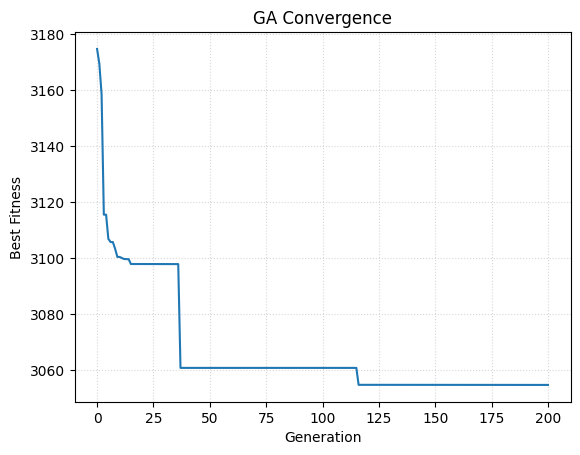

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# تابع برازش
def fitness_function(individual):
    x, y, z = individual
    return 2 * x**2 + 3 * y**3 + 5 * np.sin(z) + 7

# بازترکیب
def crossover(p1, p2, prob):
    if np.random.rand() > prob:
        return p1.copy()
    mask = np.random.rand(len(p1)) < 0.5
    return np.where(mask, p2, p1)

# عملگر جهش
def mutation(ind, bounds, prob):
    new = ind.copy()
    for i in range(len(ind)):
        if np.random.rand() < prob:
            new[i] = np.random.uniform(bounds[0][i], bounds[1][i])
    return new

# انتخاب والدها با تورنومنت
def selection(pop, fit, n_parents):
    parents = []
    for _ in range(n_parents):
        idx = np.random.choice(len(pop), size=3, replace=False)
        winner = idx[np.argmin(fit[idx])]
        parents.append(pop[winner])
    return np.array(parents)

# الگوریتم ژنتیک اصلی
def genetic_algorithm(func, bounds, gens=200, pop_size=100, cx_prob=0.7, mut_prob=0.1, seed=42):
    np.random.seed(seed)
    low, high = bounds
    dim = len(low)
    pop = np.random.uniform(low, high, (pop_size, dim))  # تولید جمعیت اولیه
    fit = np.array([func(ind) for ind in pop])
    hist = [fit.min()]

    for g in range(gens):
        par = selection(pop, fit, pop_size)
        children = []
        for _ in range(pop_size):
            p1, p2 = par[np.random.randint(0, pop_size)], par[np.random.randint(0, pop_size)]
            child = crossover(p1, p2, cx_prob)
            child = mutation(child, bounds, mut_prob)
            children.append(child)
        combined = np.vstack((pop, children))
        c_fit = np.array([func(ind) for ind in combined])
        order = np.argsort(c_fit)
        pop = combined[order[:pop_size]]   # انتخاب بهترین‌ها
        fit = c_fit[order[:pop_size]]
        hist.append(fit.min())
    best_idx = np.argmin(fit)
    return pop[best_idx], fit[best_idx], hist

# گرفتن محدوده‌ها از کاربر
x_min = float(input("x min: "))
x_max = float(input("x max: "))
y_min = float(input("y min: "))
y_max = float(input("y max: "))
z_min = float(input("z min: "))
z_max = float(input("z max: "))

bounds = [[x_min, y_min, z_min], [x_max, y_max, z_max]]

# اجرای الگوریتم
best, value, history = genetic_algorithm(fitness_function, bounds)

print("Best:", best, "Value:", value)

# رسم نمودار همگرایی
plt.plot(history)
plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.title("GA Convergence")
plt.grid(True, linestyle=":", alpha=0.5)
plt.show()
